# Filbin et al. 2018 — H3-K27M Glioma
## 03 · Embryonic-module signatures & Gate 2

Score the three developmental modules — **Gast** (gastrulation), **pSom** (posterior somitogenesis),
**Crest** (neural crest) — with `score_genes` against the union control pool. **Gate 2** asks
(visually): does the module pattern appear — a Gast/pSom hub diverging into two arms, with Crest high
at a tip? Signatures are read both raw (deliverable panels, Puram style) and **smoothed** (geography).

In [ ]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # e.g. Filbin2018_Brain-9  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Brain)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir] * 6))                 # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Filbin2018_Brain-9 | category: Brain


### Load manifold

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print(adata)

AnnData object with n_obs × n_vars = 1998 × 21224
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'housekeeping_gene_expression', 'opc_variable', 'oc_like', 'ac_like', 'opc_like', 'celltype', 'leiden', 'cycling', 'compartment', 'opc_like_sm', 'ac_like_sm', 'oc_like_sm', 'lz', 'GSE162534', 'GSE229103', 'rRNAModifications', 'Gast', 'pSom', 'Crest', 'Gast_sm', 'pSom_sm', 'Crest_sm', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'lz', 'milestones_colors', 'neighbors', 'pca', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'


### Score Gast / pSom / Crest (union control pool)
Read the `hsapiens` column of each gene set, drop NaN/dupes, keep genes present in the data. The
`union` set is the control gene pool for `score_genes` (reference protocol).

In [ ]:
feat_fn = sorted(glob.glob(os.path.join(FEAT, '*.csv')))
get_src = lambda fn: os.path.basename(fn).replace('.csv', '')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates().dropna()
feat_dict = {get_src(fn): get_feat(fn) for fn in feat_fn}
g_ref = feat_dict['union'][feat_dict['union'].isin(adata.var_names)]
for src, df_src in feat_dict.items():
    if src == 'union': continue
    g = df_src[df_src.isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=src, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print('%s: %d / %d genes recovered (control pool %d)' % (src, g.size, df_src.size, g_ref.size))
# friendly aliases + smoothed versions for geography
adata.obs['Gast'] = adata.obs.GSE162534; adata.obs['pSom'] = adata.obs.GSE229103; adata.obs['Crest'] = adata.obs.rRNAModifications
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg == 0] = 1
for k in ['Gast', 'pSom', 'Crest']:
    adata.obs[k + '_sm'] = (A @ adata.obs[k].values) / deg

GSE162534: 78 / 81 genes recovered (control pool 232)
GSE229103: 93 / 98 genes recovered (control pool 232)
rRNAModifications: 102 / 104 genes recovered (control pool 232)


### Gate 2 — module geography (smoothed, read visually off the fork)
Gast/pSom co-express at the **Mixed hub / root**, then diverge along the arms; **Crest peaks at the
OC-arm tip** (terminal readout). This is the branching module pattern — **Gate 2 GO**.

per-subtype smoothed module means:
          Gast_sm  pSom_sm  Crest_sm      t
celltype                                   
AC-like     0.046    0.210     0.045  2.597
Mixed       0.032    0.232     0.068  1.126
OC-like    -0.019    0.187     0.164  4.310


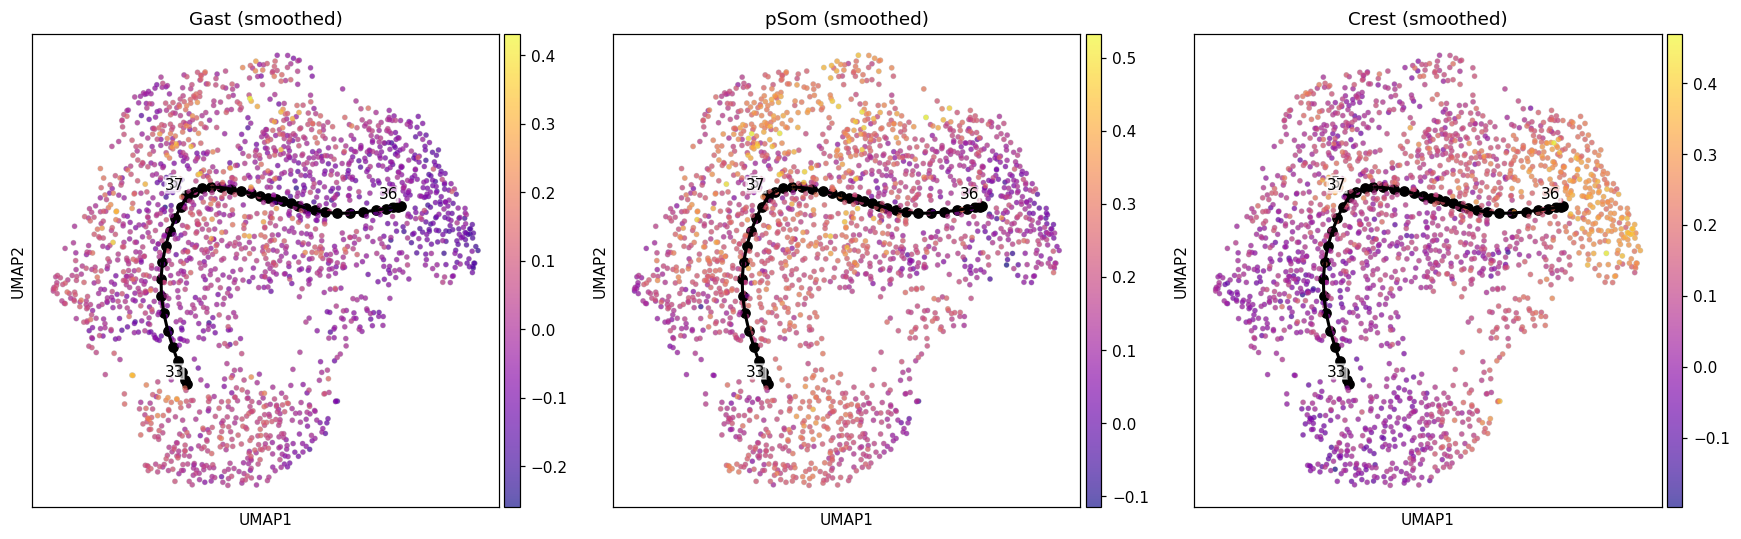

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, c in zip(axs, ['Gast_sm', 'pSom_sm', 'Crest_sm']):
    scf.pl.graph(adata, basis='umap', ax=ax, show=False)
    sc.pl.umap(adata, color=c, ax=ax, show=False, size=45, cmap='plasma', alpha=.65)
    ax.set_title(c.replace('_sm', ' (smoothed)'))
plt.tight_layout(); plt.show()
# arm-level smoothed means confirm: Gast/pSom co-vary; Crest terminal on OC arm
print('per-subtype smoothed module means:')
print(adata.obs.groupby('celltype', observed=True)[['Gast_sm', 'pSom_sm', 'Crest_sm', 't']].mean().round(3).to_string())

### `Gast_signature.pdf` (+ colorbar)

saved Gast_signature.pdf


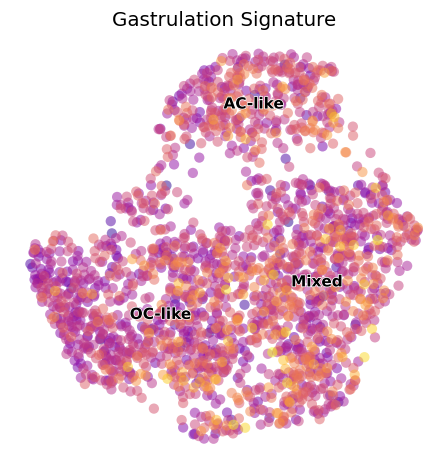

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='GSE162534', cmap='plasma', alpha=.5, size=180, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Gastrulation Signature', size=13)
fig.savefig(os.path.join(pth_fig, 'Gast_signature.pdf'), bbox_inches='tight'); plt.show()
print('saved Gast_signature.pdf')

saved colorbars/Gast_colorbar.pdf


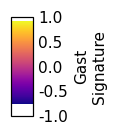

In [ ]:
fig = plt.figure(figsize=(.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax=cax)
cb.ax.tick_params(which='both', size=0)
cb.set_label('Gast\nSignature')
ticks = np.asarray([-1, -.5, 0, .5, 1])
cb.set_ticks(ticks, labels=ticks)
cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Gast_colorbar.pdf'), bbox_inches='tight'); plt.show()
print('saved colorbars/Gast_colorbar.pdf')

### `pSom_signature.pdf` (+ colorbar)

saved pSom_signature.pdf


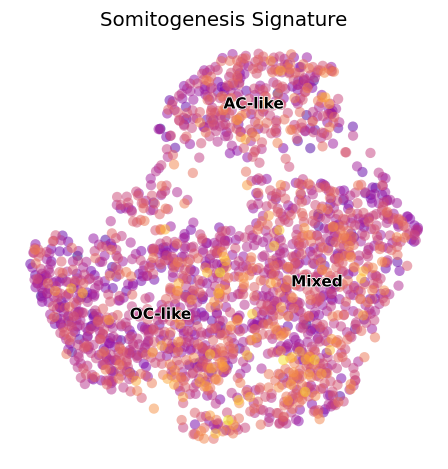

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='GSE229103', cmap='plasma', alpha=.5, size=180, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Somitogenesis Signature', size=13)
fig.savefig(os.path.join(pth_fig, 'pSom_signature.pdf'), bbox_inches='tight'); plt.show()
print('saved pSom_signature.pdf')

saved colorbars/pSom_colorbar.pdf


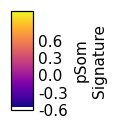

In [ ]:
fig = plt.figure(figsize=(.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax=cax)
cb.ax.tick_params(which='both', size=0)
cb.set_label('pSom\nSignature')
ticks = np.asarray([-.6, -.3, 0, .3, .6])
cb.set_ticks(ticks, labels=ticks)
cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'pSom_colorbar.pdf'), bbox_inches='tight'); plt.show()
print('saved colorbars/pSom_colorbar.pdf')

### `Crest_signature.pdf` (+ colorbar)

saved Crest_signature.pdf


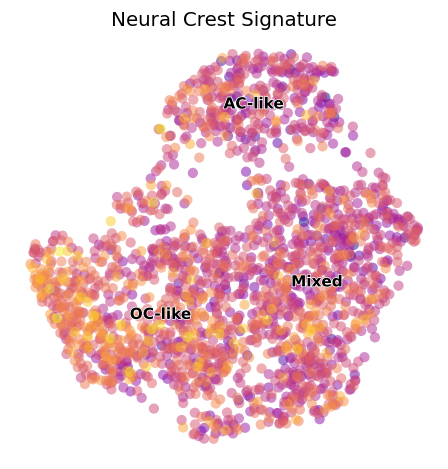

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='rRNAModifications', cmap='plasma', alpha=.5, size=180, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Neural Crest Signature', size=13)
fig.savefig(os.path.join(pth_fig, 'Crest_signature.pdf'), bbox_inches='tight'); plt.show()
print('saved Crest_signature.pdf')

saved colorbars/Crest_colorbar.pdf


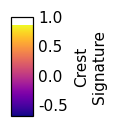

In [ ]:
fig = plt.figure(figsize=(.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax=cax)
cb.ax.tick_params(which='both', size=0)
cb.set_label('Crest\nSignature')
ticks = np.asarray([-.5, 0, .5, 1])
cb.set_ticks(ticks, labels=ticks)
cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Crest_colorbar.pdf'), bbox_inches='tight'); plt.show()
print('saved colorbars/Crest_colorbar.pdf')

### Save signatures

In [ ]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (1998, 21224)
